# Checkpoint 1: Visual PEFT pada Flowers102

**Kelompok 1**

- Alif Negifta Wibawaputra
- Charleen Samaeri Gulo

### Daftar Isi

| No. | Bagian |
| ---: | --- |
| 1 | [Latar Belakang](#sec-latar-belakang) |
| 2 | [Tujuan](#sec-tujuan) |
| 3 | [Dataset](#sec-dataset) |
| 4 | [Metodologi & Eksperimen](#sec-metodologi-eksperimen) |
| 5 | [Hasil & Evaluasi](#sec-hasil-evaluasi) |
| 6 | [Diskusi](#sec-diskusi) |
| 7 | [Kesimpulan](#sec-kesimpulan) |
| 8 | [Future Works](#sec-future-works) |
| 9 | [Output](#sec-output) |

<a id="sec-latar-belakang"></a>

## Latar Belakang

Fine-tuning mengadaptasi model pretrained ke task baru. Ketika data berlabel sedikit, memperbarui seluruh backbone dapat membutuhkan banyak parameter dan meningkatkan risiko overfitting. Parameter-efficient fine-tuning (PEFT) membatasi parameter yang dilatih, misalnya melalui pembaruan low-rank atau transformasi fitur.

Paper [Mai et al., CVPR 2025](https://arxiv.org/abs/2409.16434) membandingkan berbagai metode PEFT menggunakan protokol tuning yang seragam. Dua temuan yang relevan adalah accuracy antarmetode yang berdekatan dan prediksi yang tetap dapat saling melengkapi. Paper juga menguji many-shot learning serta distribution shift.

Flowers102 dipakai sebagai task awal untuk memeriksa implementasi pada klasifikasi gambar dengan label terbatas. Linear probing menjadi baseline adaptasi classifier. LoRA mempelajari pembaruan proyeksi attention, sedangkan SSF mempelajari scale dan shift fitur. Ketiganya memberi perbandingan antara classifier saja dan dua mekanisme adaptasi backbone.

Flowers102 merupakan task dengan accuracy tinggi dalam paper. Karena itu, selisih jumlah prediksi benar dapat kecil. Analisis mencakup kualitas probabilitas dan pola error, selain accuracy. Lingkup checkpoint ini adalah partial reproduction dengan analisis eksploratif pada satu task dan satu konfigurasi tetap per metode.

<a id="sec-tujuan"></a>

## Tujuan

Pertanyaan penelitian: pada konfigurasi training tetap, bagaimana Linear, LoRA, dan SSF berbeda dalam kualitas probabilitas dan pola error ketika accuracy validation sama?

1. Membandingkan accuracy, macro recall, kualitas probabilitas, dan jumlah parameter yang dilatih.
2. Mendeskripsikan perbedaan lokasi error pada validation yang sama.
3. Mengeksplorasi accuracy dan kualitas probabilitas melalui probability averaging serta logit averaging.

Konfigurasi tetap membatasi variasi konfigurasi training, tetapi tidak menjamin setiap metode telah dituning dengan sama baiknya. Eksperimen ini tidak menentukan anggaran parameter optimal atau metode terbaik setelah tuning.

Hasil utama menggunakan checkpoint epoch 100. Best checkpoint dipakai sebagai diagnostik. Ketiga metode telah menyelesaikan training. ConvPass berhenti pada epoch 92 dan dikeluarkan dari perbandingan ini.

<a id="sec-dataset"></a>

## Dataset

[Oxford Flowers102](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/) digunakan melalui [mirror processed VTAB-1K](https://huggingface.co/datasets/XiN0919/VTAB-1k), revisi a1c257fbbeebd3260c0a201fe6a6c9916b56eee7. Label merupakan indeks kelas 0-101. Training berisi 800 gambar dan validation berisi 200 gambar.

Persiapan pada A100 mencakup pemeriksaan arsip, daftar split, label, sampel gambar yang dapat dibuka, serta duplikasi isi file train-validation. Notebook membaca manifest dan 13 foto terpilih dari proses tersebut. Hash foto lokal, urutan label validation, dan hash split diverifikasi terhadap snapshot eksperimen.

Metadata dan sampel file test pernah diperiksa untuk integritas. Test tidak digunakan untuk training, pemilihan konfigurasi, atau pengukuran performa. Duplikasi isi file train-test dan kesamaan anggota split mirror terhadap arsip penulis belum terverifikasi.

### Setup analisis

Run All menggunakan dependensi pada requirements-analysis.txt. Analisis berjalan di CPU dari snapshot lokal, tanpa menjalankan training atau mengunduh dataset.

In [1]:
from pathlib import Path
import json
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from IPython.display import display, Markdown, Image as NotebookImage

ROOT = Path.cwd().resolve()
if not (ROOT / "results/checkpoint1").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "results/checkpoint1").is_dir(), "Jalankan dari root proyek atau folder notebooks."
sys.path.insert(0, str(ROOT / "scripts"))
import checkpoint_analysis as analysis
import checkpoint_figures as figures

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 10)
plt.style.use("seaborn-v0_8-whitegrid")
exports = analysis.AssetExporter(ROOT)
snapshot = analysis.load_dataset_snapshot(ROOT)
runs = analysis.load_completed_runs(ROOT, snapshot)

def show_asset(fig, name, section, caption, caveat="", source="results/checkpoint1: stored epoch-100 results, histories and logits"):
    exports.figure(fig, name, section, caption, caveat, source)
    plt.show()
    plt.close(fig)

def show_diagram(name, section, caption, caveat="", source="Mermaid source"):
    path = exports.diagram(name, section, caption, caveat, source)
    display(NotebookImage(filename=str(path), width=1100))

print("Python", platform.python_version(), "| NumPy", np.__version__, "| Pandas", pd.__version__)
print("Matplotlib", matplotlib.__version__, "| SciPy", scipy.__version__)
print("Snapshot terverifikasi:", ", ".join(runs), "| 100 epoch | seed 42")


Python 3.11.15 | NumPy 2.4.6 | Pandas 3.0.5
Matplotlib 3.11.2 | SciPy 1.17.1
Snapshot terverifikasi: Linear, LoRA, SSF | 100 epoch | seed 42


,Split,Gambar,Kelas teramati,Kelas tanpa sampel,Minimum gambar per kelas teramati,Maksimum gambar per kelas
0,train,800,102,0,5,10
1,validation,200,90,12,1,5


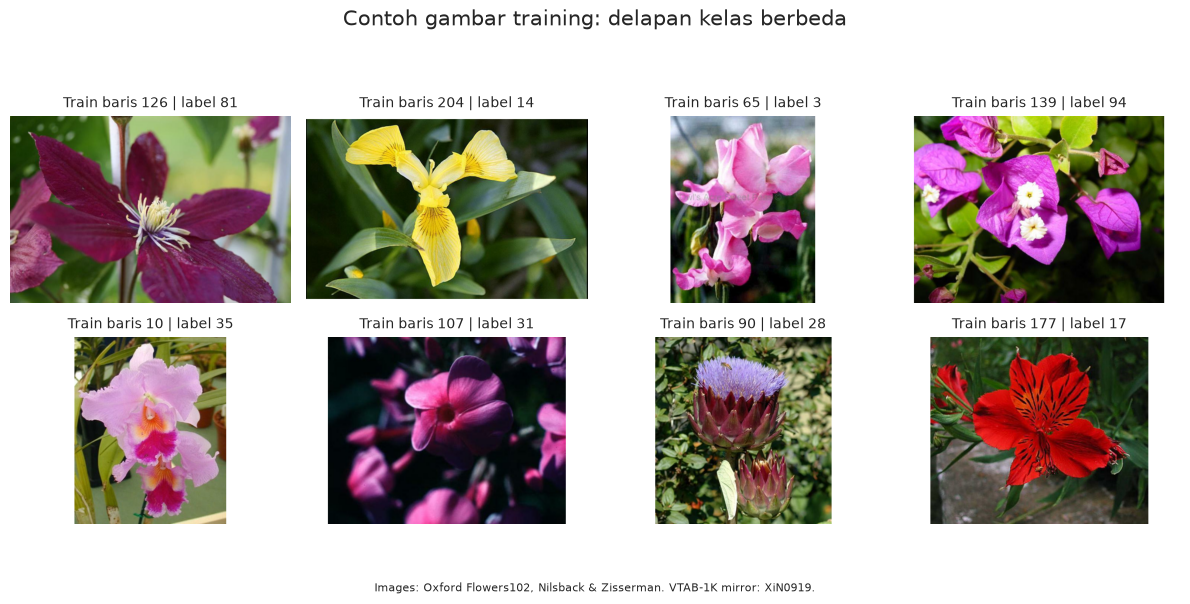

In [2]:
data_summary = analysis.dataset_summary(snapshot)
exports.table(data_summary, "dataset-summary", "Dataset",
              "Jumlah gambar dan cakupan kelas pada training dan validation.",
              "Kelas tanpa sampel validation tidak dapat dinilai.", "Verified split manifests")
display(data_summary)
show_asset(analysis.plot_dataset_examples(snapshot), "dataset-examples", "Dataset",
           "Delapan contoh dari kelas training yang berbeda.",
           "Foto ilustratif, dengan padding putih untuk panel.",
           "Oxford Flowers102 via pinned XiN0919/VTAB-1k mirror")

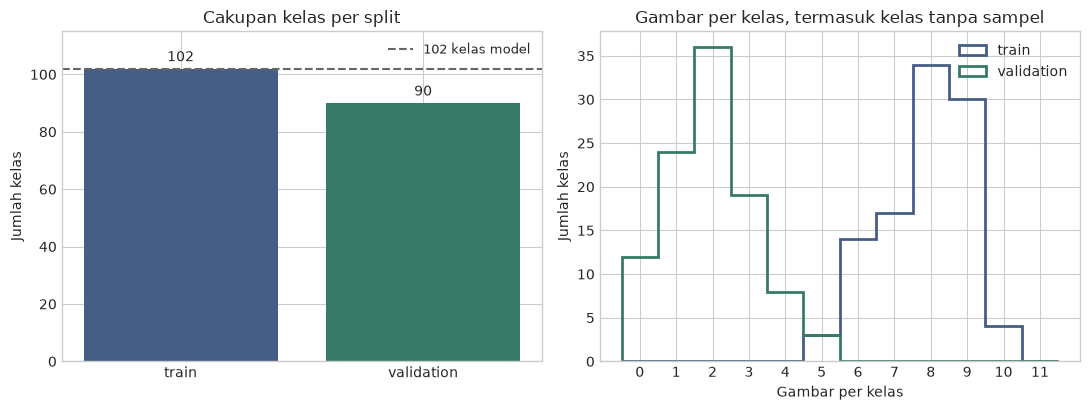

**Observasi:** training mencakup 102 kelas dengan 5-10 gambar per kelas. Validation mencakup 90 kelas, dengan 1-5 gambar per kelas yang teramati. Sebanyak 12 kelas tidak memiliki sampel validation. Satu kesalahan dapat mengubah recall suatu kelas secara besar ketika support-nya hanya satu atau dua gambar.

Duplikasi isi file train-validation: 0
Keanggotaan split terhadap arsip penulis: unverified


In [3]:
show_asset(analysis.plot_class_coverage(snapshot), "class-coverage", "Dataset",
           "Cakupan kelas serta distribusi jumlah gambar per kelas.",
           "Distribusi validation tidak menguji semua 102 kelas.",
           "dataset_audit.json and train/validation row manifests")
train_counts = snapshot["records"]["train"]["label"].value_counts()
val_counts = snapshot["records"]["validation"]["label"].value_counts()
display(Markdown(
    f"**Observasi:** training mencakup {len(train_counts)} kelas dengan {int(train_counts.min())}-{int(train_counts.max())} gambar per kelas. "
    f"Validation mencakup {len(val_counts)} kelas, dengan {int(val_counts.min())}-{int(val_counts.max())} gambar per kelas yang teramati. "
    f"Sebanyak {102 - len(val_counts)} kelas tidak memiliki sampel validation. "
    "Satu kesalahan dapat mengubah recall suatu kelas secara besar ketika support-nya hanya satu atau dua gambar."
))
print("Duplikasi isi file train-validation:", snapshot["audit"]["train_val_identical_file_content_count"])
print("Keanggotaan split terhadap arsip penulis:", snapshot["audit"]["split_membership_matches_authors_seed_9526"])

<a id="sec-metodologi-eksperimen"></a>

## Metodologi & Eksperimen

### Backbone dan Trainable Parameters

Backbone yang digunakan adalah ViT-B/16 pretrained secara supervised pada ImageNet-21K. Gambar 224 × 224 dibagi menjadi 196 patch berukuran 16 × 16. Embedding patch dan token CLS diproses oleh 12 blok Transformer dengan lebar fitur 768. Fitur CLS digunakan oleh classifier linear 102 kelas.

- **Linear probing:** hanya classifier yang diperbarui. Baseline ini memeriksa kemampuan fitur pretrained tanpa mengadaptasi parameter di dalam backbone.
- **LoRA:** kode native menggunakan proyeksi A berukuran 768 → 8 dan B berukuran 8 → 2304 di setiap blok. Delta dibagi menjadi Q, K, dan V. Pembaruan berbentuk low-rank dengan merge factor 1 dan dropout input 0,1.
- **SSF:** parameter scale dan shift dilatih pada lokasi fitur native, dengan bentuk $z'=\gamma\odot z+\beta$. Parameter pretrained tetap frozen.

Classifier memuat $768\times102+102=78.438$ parameter. LoRA menambahkan $12\times(768\times8+8\times2304)=294.912$ parameter. Setiap pasangan scale dan shift pada fitur berdimensi d menambah 2d parameter. Penjumlahan seluruh lokasi native SSF menghasilkan 205.824 parameter. Semua metode melatih classifier yang diinisialisasi dengan seed tersendiri agar identik.

Penjelasan LoRA mengikuti [kode yang dipin](https://github.com/OSU-MLB/ViT_PEFT_Vision/blob/cea7e21b2ddecef8172f5d177da5a29d531c4279/model/lora.py). Target proyeksi dan inisialisasi mengikuti constructor native secara lengkap. Pengali merge factor adalah skala delta, dan tidak menyatakan bahwa bobot sudah digabung untuk inferensi.

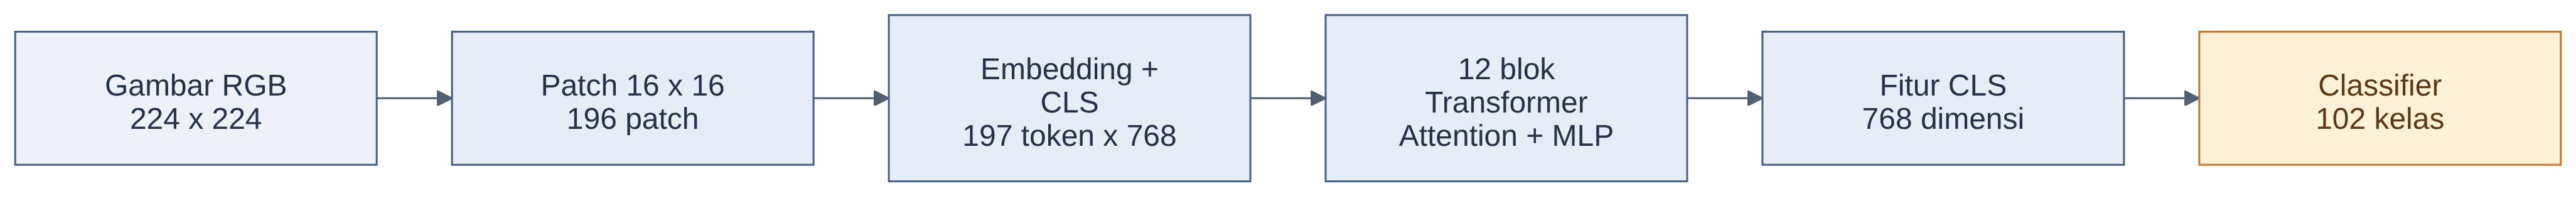

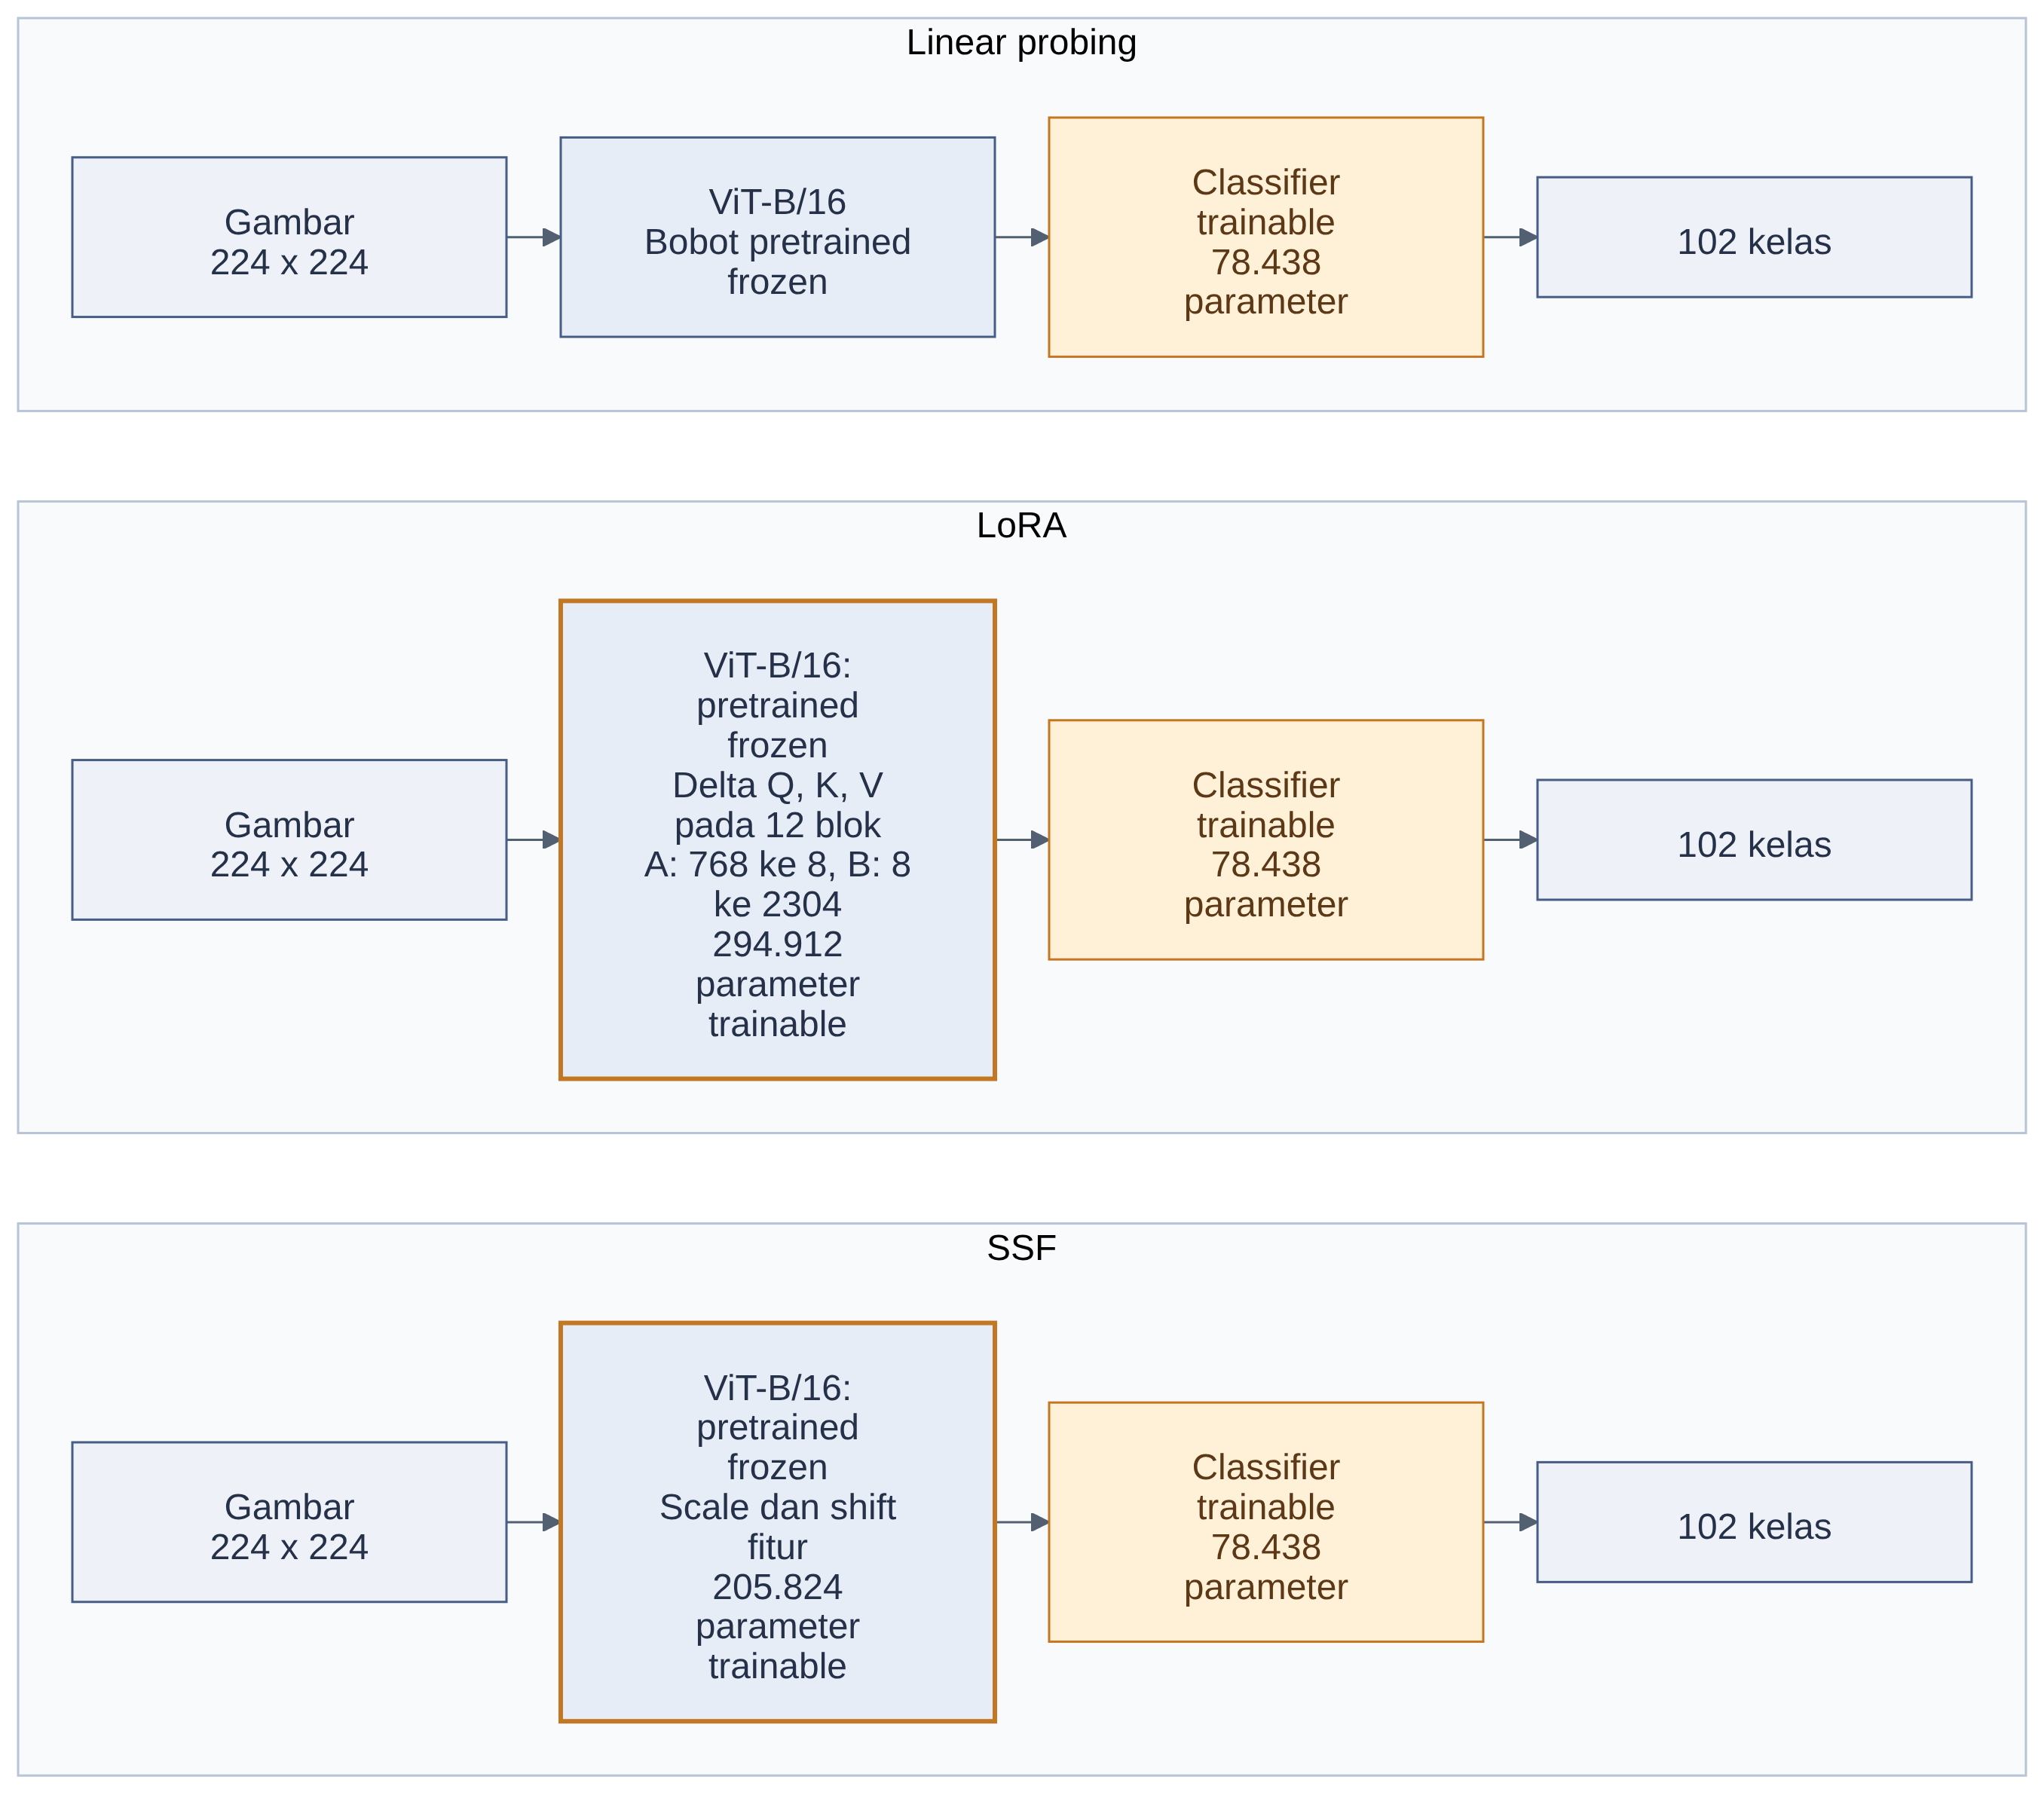

In [4]:
show_diagram("vit-backbone", "Metodologi & Eksperimen",
           "Alur gambar, embedding patch, Transformer dan classifier pada ViT-B/16.",
           "Diagram merangkum alur utama.", "Pinned upstream ViT-B/16 architecture and image transform")
show_diagram("method-diagram", "Metodologi & Eksperimen",
           "Perbedaan parameter frozen dan trainable pada tiga metode.",
           "Skema mengikuti implementasi native.", "Pinned model/lora.py, model/ssf.py and parameter boundaries")

### Protokol training

Training menggunakan split dan backbone awal yang sama, seed 42, 100 epoch, AdamW, cosine decay, dan effective batch 64. Preprocessing berupa resize bicubic menjadi 224 × 224 dan ToTensor. Normalization serta augmentation gambar dinonaktifkan mengikuti default VTAB upstream. Resize menetapkan ukuran masukan tanpa mempertahankan rasio aspek asli.

Linear menggunakan batch langsung 64. LoRA dan SSF menggunakan microbatch 8. Loss cross-entropy setiap microbatch dibobotkan menurut jumlah sampelnya sebelum gradien diakumulasi. Untuk delapan microbatch berukuran sama, masing-masing menyumbang seperdelapan gradien effective batch. Optimizer melakukan satu update setelah seluruh microbatch selesai.

~~~text
inisialisasi model, muat backbone pretrained, reset classifier
freeze parameter pretrained, aktifkan classifier dan parameter metode
untuk setiap epoch:
    acak training, bentuk effective batch 64 dari tensor gambar
    untuk setiap effective batch:
        kosongkan gradien
        untuk setiap microbatch:
            logits = model(gambar)
            loss = cross_entropy(logits, label)
            backward(loss × ukuran_microbatch / ukuran_effective_batch)
        optimizer.step()
    evaluasi validation dalam eval mode tanpa gradien
    scheduler.step(epoch)
    simpan last checkpoint dan best checkpoint jika accuracy meningkat
~~~

Drop-last membuat 768 dari 800 gambar yang diacak berkontribusi setiap epoch. Terdapat 12 optimizer update per epoch, sehingga totalnya 1.200 update. Gambar yang tidak masuk batch terakhir dapat berbeda antar epoch. Gradient accumulation menjaga pembobotan loss, tetapi trajectory tidak dijamin identik dengan batch langsung karena dropout draws dan penjumlahan floating point.

Implementasi tersedia pada [runner training](https://github.com/alifnw/peft-vision-flowers102/blob/main/scripts/train_validation.py), [batas parameter metode](https://github.com/alifnw/peft-vision-flowers102/blob/main/scripts/peft_methods.py), dan [gradient accumulation](https://github.com/alifnw/peft-vision-flowers102/blob/main/scripts/gradient_accumulation.py). Sel analisis dalam notebook tidak memanggil runner tersebut.

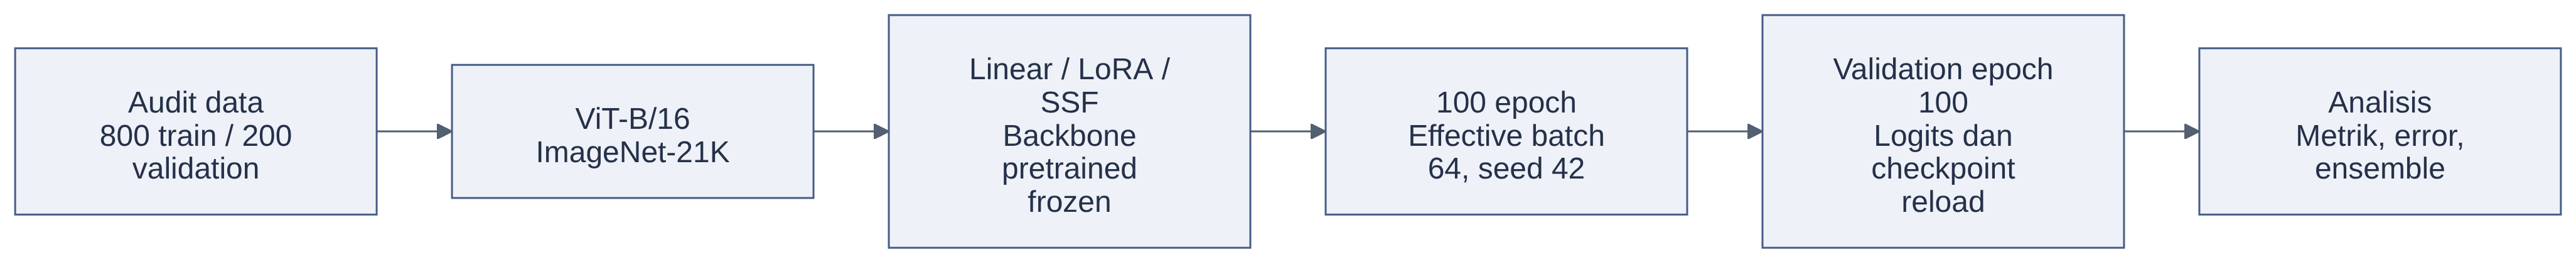

In [5]:
show_diagram("experiment-flow", "Metodologi & Eksperimen",
           "Urutan persiapan data, training dan analisis validation epoch 100.",
           "Tidak mencakup hyperparameter search, retraining trainval atau evaluasi test.")

### Konfigurasi dan pertimbangan

Backbone, AdamW, effective batch, cosine schedule, dan anggaran 100 epoch mengikuti protokol VTAB paper. AdamW menerapkan weight decay terpisah dari pembaruan gradien adaptif. Learning rate mengatur skala update, sedangkan weight decay memberikan regularisasi parameter yang dilatih.

Learning rate 0,001, weight decay 0,0001, dan LoRA rank 8 merupakan pilihan baseline dari grid resmi. Rank membatasi kapasitas pembaruan low-rank. Tidak ada sweep yang membuktikan bahwa pilihan ini optimal untuk Flowers102.

Warmup 10 epoch, minimum LR 1e-5, resize, dan perilaku normalization mengikuti default upstream. Warmup menaikkan LR pada awal training sebelum cosine decay. Drop path 0,1 merupakan regularisasi pada jalur residual, berbeda dari augmentation gambar. LoRA juga memiliki dropout 0,1 pada input cabang low-rank.

Microbatch 8, workers 0, pin-memory nonaktif, satu thread, dan checkpoint/resume merupakan penyesuaian pada node A100 bersama dengan batas host RAM 16 GiB. Seluruh run menggunakan FP32. Pengaruh penyesuaian ini terhadap kualitas belum diisolasi melalui ablation.

Rincian sumber dan konsekuensi tiap pengaturan tersedia pada [catatan konfigurasi](https://github.com/alifnw/peft-vision-flowers102/blob/main/docs/CONFIGURATION_NOTES.md).

In [6]:
decisions = analysis.configuration_decisions(runs)
exports.table(decisions, "configuration-decisions", "Metodologi & Eksperimen",
              "Konfigurasi aktual, sumber pemilihan dan konsekuensinya.",
              "Pilihan dari grid belum menjadi hasil tuning optimum.",
              "Run configs, pinned upstream source and Mai et al. Appendix A")
display(decisions[["Kategori", "Pengaturan", "Nilai aktual"]])
comparison = analysis.paper_comparison()
exports.table(comparison, "paper-comparison", "Metodologi & Eksperimen",
              "Perbedaan protokol paper dan eksperimen checkpoint.",
              "Validation checkpoint tidak langsung sebanding dengan hasil test paper.",
              "Mai et al. sections 3-4 and Appendix A/C")
display(comparison.loc[comparison["Aspek"].isin(
    ["Lingkup", "Pemilihan konfigurasi", "Skor yang dilaporkan", "Error diversity analysis"])])

,Kategori,Pengaturan,Nilai aktual
0,Paper,Backbone,"ViT-B/16, supervised ImageNet-21K"
1,Paper,Optimizer,AdamW
2,Paper,Epoch,100
3,Paper,Scheduler,Cosine decay
4,Pilihan dalam grid,Learning rate,0.001
5,Pilihan dalam grid,Weight decay,0.0001
6,Pilihan dalam grid,LoRA rank,8
7,Default upstream,LoRA dropout / scale,0.1 / merge_factor=1
8,Paper,Drop path,0.1
9,Default upstream,Warmup,"10 epoch, LR awal 1e-06"


,Aspek,Paper,Checkpoint 1
0,Lingkup,"19 task VTAB, full FT, linear dan 14 metode PEFT","Flowers102, Linear, LoRA dan SSF"
1,Pemilihan konfigurasi,Hyperparameter search pada 800 train / 200 validation,"Satu konfigurasi tetap, tanpa search"
2,Skor yang dilaporkan,Retrain pada 1.000 gambar dan evaluasi original test,Validation epoch 100 dari 800 train
4,Error diversity analysis,"Caption menyebut majority vote, rincian Figure 4 Appendix C memakai average logits",Error overlap serta probability averaging dan logits pada validation


### Reproducibility Checks

Hash classifier awal dan frozen backbone pada hasil yang dicatat harus sama antarmetode. Label pada setiap baris logits harus cocok dengan manifest validation. Logits dari checkpoint terakhir juga dibandingkan dengan file prediksi setelah checkpoint dimuat ulang.

Pemeriksaan backbone merujuk pada hash dan status yang direkam oleh runner saat training. CPU analysis memverifikasi konsistensi artefak tersebut dan membandingkan kedua array logits. Notebook tidak memuat ulang model ViT dari checkpoint biner.

Runner saat ini menyediakan referensi inisialisasi opsional melalui argumen reference-result. Perbaikan portabilitas dilakukan setelah eksperimen tercatat. Provenance lama tetap menyimpan hash source yang benar-benar digunakan pada masing-masing run.

In [7]:
provenance_checks = analysis.provenance_table(runs)
exports.table(provenance_checks, "provenance-checks", "Metodologi & Eksperimen",
              "Hash inisialisasi tercatat, kesamaan urutan target dan selisih logits setelah reload.",
              "Hash backbone berasal dari pemeriksaan runner saat training.",
              "Original result/provenance JSON and validation_last_reloaded.npz")
compact_checks = provenance_checks.copy()
compact_checks["classifier_initial_sha256"] = compact_checks["classifier_initial_sha256"].str[:12]
display(compact_checks[["method", "classifier_initial_sha256",
                        "recorded_backbone_unchanged", "reload_max_abs_logit_difference"]].rename(columns={
    "method": "Metode", "classifier_initial_sha256": "Hash classifier awal",
    "recorded_backbone_unchanged": "Backbone tetap", "reload_max_abs_logit_difference": "Selisih logits reload"}))

,Metode,Hash classifier awal,Backbone tetap,Selisih logits reload
0,Linear,0293216d6e6d,True,0.0
1,LoRA,0293216d6e6d,True,0.0
2,SSF,0293216d6e6d,True,0.0


<a id="sec-hasil-evaluasi"></a>

## Hasil & Evaluasi

### Metrik

Accuracy merupakan proporsi prediksi kelas teratas yang benar. Macro recall menghitung recall tiap kelas, lalu merata-ratakannya atas kelas yang memiliki sampel validation. Kelas dengan support nol tidak diberi recall nol.

Negative log-likelihood menilai probabilitas label aktual. Multiclass Brier menjumlahkan squared error atas 102 kelas sebelum merata-ratakannya atas gambar:

$$\mathrm{NLL}=-\frac{1}{N}\sum_i\log p(y_i\mid x_i),\qquad
\mathrm{Brier}=\frac{1}{N}\sum_i\sum_{k=1}^{102}(p_{ik}-\mathbb{1}[y_i=k])^2.$$

NLL dan Brier yang lebih rendah menunjukkan skor probabilitas yang lebih baik pada data evaluasi. Keduanya tidak mengisolasi calibration dari sharpness. Seluruh metrik utama dihitung ulang dari logits epoch 100 menggunakan log-softmax stabil.

Interval Wilson 95% merangkum ketidakpastian binomial pada 200 gambar dengan asumsi observasi independen. Variasi seed, pemilihan split, dan dependensi antargambar tidak tercakup.

In [8]:
summary = analysis.metrics_table(runs)
exports.table(summary, "method-metrics", "Hasil & Evaluasi",
              "Metrik epoch 100, parameter terlatih dan catatan runtime.",
              "Satu seed dan satu split. Catatan resource bukan benchmark efisiensi terkontrol.")
display(summary[["method", "correct", "accuracy_percent", "macro_recall_observed_percent",
                 "nll", "brier_multiclass_sum", "trainable_including_head"]].round(5).rename(columns={
    "method": "Metode", "correct": "Benar", "accuracy_percent": "Accuracy (%)",
    "macro_recall_observed_percent": "Macro recall (%)", "nll": "NLL",
    "brier_multiclass_sum": "Brier", "trainable_including_head": "Parameter dilatih"}))
assert summary["correct"].tolist() == [198, 198, 198]

,Metode,Benar,Accuracy (%),Macro recall (%),NLL,Brier,Parameter dilatih
0,Linear,198,99.0,99.40741,0.11620,0.03572,78438
1,LoRA,198,99.0,98.66667,0.04099,0.01373,373350
2,SSF,198,99.0,98.33333,0.03558,0.01345,284262


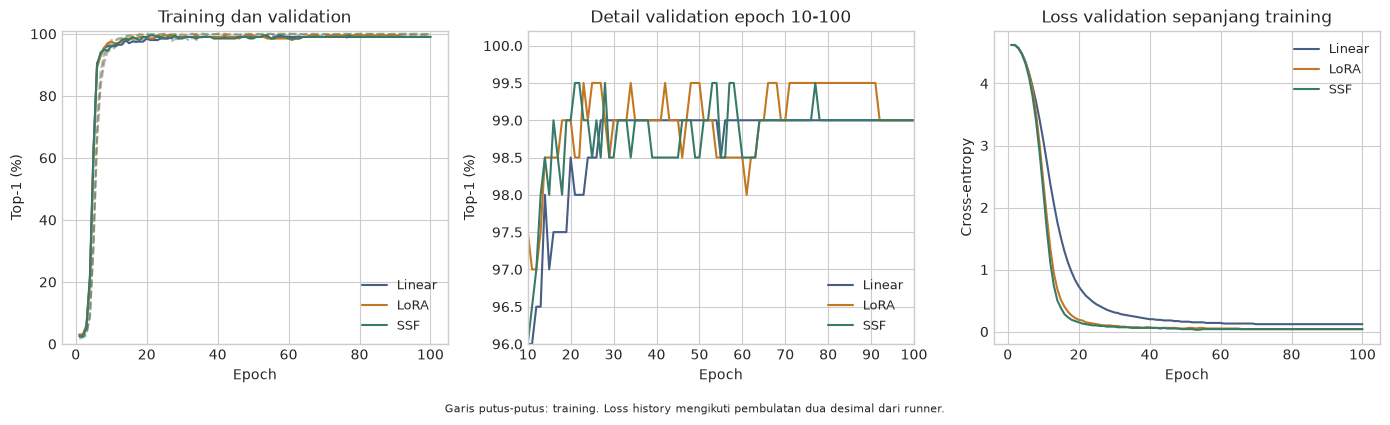

**Observasi:** accuracy validation pertama kali mencapai 99% pada epoch 27 untuk Linear, 18 untuk LoRA, dan 16 untuk SSF. Ketiganya berakhir pada 99%. Epoch yang lebih awal menunjukkan kebutuhan update yang berbeda pada run ini. Hal tersebut belum menunjukkan waktu komputasi yang lebih singkat atau kestabilan pada seed lain. Perubahan 0,5 poin persentase pada validation setara satu gambar.

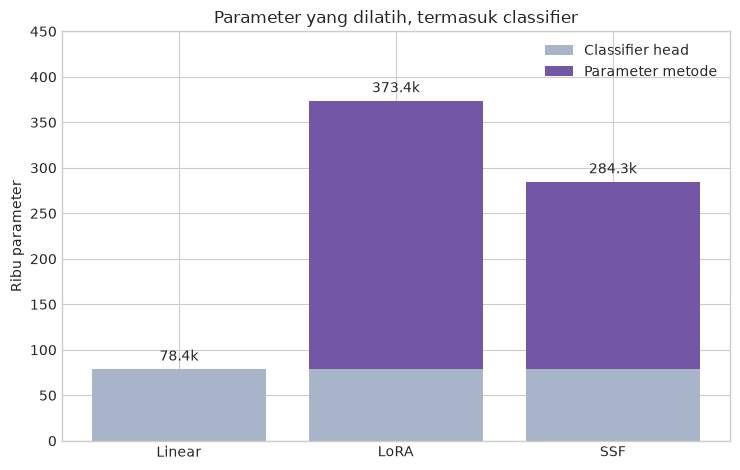

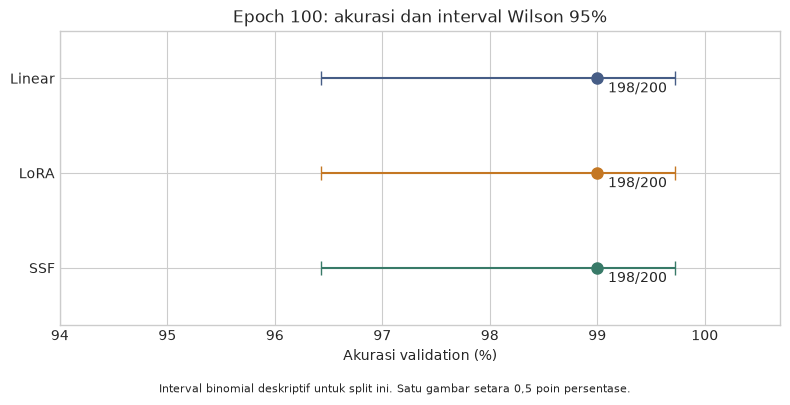

**Interpretasi:** Linear melatih parameter paling sedikit pada accuracy akhir yang sama. LoRA dan SSF mengubah representasi melalui parameter tambahan. Jumlah parameter dan accuracy saja belum cukup untuk menentukan pilihan ketika kualitas probabilitas juga penting.

In [9]:
show_asset(figures.learning_curves(runs), "learning-curves", "Hasil & Evaluasi",
           "Dinamika training dan validation untuk tiga metode.",
           "Loss pada history dibulatkan dua desimal oleh runner.", "Stored history.csv for all three methods")
first_99 = {name: int(run["history"].loc[run["history"]["val_top1"] >= 99, "epoch"].iloc[0])
            for name, run in runs.items()}
display(Markdown(
    f"**Observasi:** accuracy validation pertama kali mencapai 99% pada epoch {first_99['Linear']} untuk Linear, "
    f"{first_99['LoRA']} untuk LoRA, dan {first_99['SSF']} untuk SSF. Ketiganya berakhir pada 99%. "
    "Epoch yang lebih awal menunjukkan kebutuhan update yang berbeda pada run ini. "
    "Hal tersebut belum menunjukkan waktu komputasi yang lebih singkat atau kestabilan pada seed lain. "
    "Perubahan 0,5 poin persentase pada validation setara satu gambar."
))
show_asset(figures.parameter_counts(summary), "parameter-counts", "Hasil & Evaluasi",
           "Parameter classifier dan parameter metode yang dilatih.",
           "Parameter count tidak mengukur FLOPs atau latency.")
show_asset(figures.final_accuracy(summary), "final-accuracy", "Hasil & Evaluasi",
           "Accuracy epoch 100 beserta interval Wilson 95%.",
           "Interval tidak mencakup variasi seed atau split.")
display(Markdown(
    "**Interpretasi:** Linear melatih parameter paling sedikit pada accuracy akhir yang sama. "
    "LoRA dan SSF mengubah representasi melalui parameter tambahan. "
    "Jumlah parameter dan accuracy saja belum cukup untuk menentukan pilihan ketika kualitas probabilitas juga penting."
))

### Probability Metrics dan Reliability

Reliability plot membandingkan rata-rata confidence kelas prediksi dengan proporsi prediksi benar dalam lima bin confidence yang tetap. ECE merangkum selisih tersebut dengan bobot jumlah sampel. Nilainya bergantung pada pembagian bin dan ukuran evaluasi.

Bin kosong tidak ditampilkan sebagai titik. Bin dengan sedikit sampel memiliki interval lebar. Tidak ada temperature scaling atau threshold yang dipasang pada validation ini. Linear dengan temperature scaling menjadi kontrol lanjutan untuk memeriksa seberapa jauh selisih skor dapat dijelaskan oleh skala confidence. Fitting memerlukan calibration data yang terpisah dari evaluasi akhir.

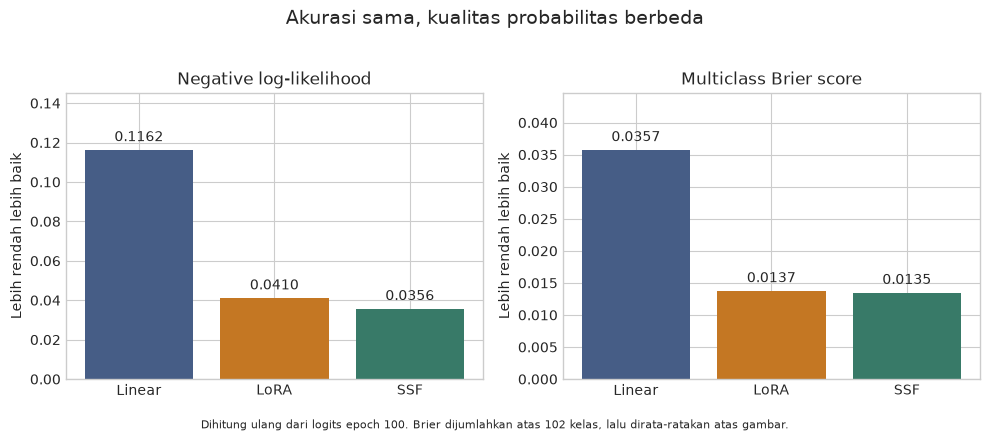

,method,nll,brier_multiclass_sum,ece_5_equal_width
0,Linear,0.116201,0.035724,0.078114
1,LoRA,0.040995,0.013731,0.024643
2,SSF,0.035582,0.013453,0.020239


**Observasi:** LoRA dan SSF memiliki NLL serta Brier lebih rendah daripada Linear pada validation ini. Accuracy hanya memeriksa kelas teratas, sedangkan kedua skor tersebut juga menilai probabilitas yang diberikan. Skor yang lebih rendah belum membuktikan calibration atau representasi yang lebih baik sebagai penyebabnya. Urutan titik estimasi tetap perlu dibaca bersama ketidakpastian dan dukungan sampelnya.

In [10]:
show_asset(figures.probability_quality(summary), "probability-quality", "Hasil & Evaluasi",
           "Perbedaan NLL dan multiclass Brier pada accuracy yang sama.",
           "Proper scores tidak mengukur calibration saja.")
display(summary[["method", "nll", "brier_multiclass_sum", "ece_5_equal_width"]].round(6))
display(Markdown(
    "**Observasi:** LoRA dan SSF memiliki NLL serta Brier lebih rendah daripada Linear pada validation ini. "
    "Accuracy hanya memeriksa kelas teratas, sedangkan kedua skor tersebut juga menilai probabilitas yang diberikan. "
    "Skor yang lebih rendah belum membuktikan calibration atau representasi yang lebih baik sebagai penyebabnya. Urutan titik estimasi tetap perlu dibaca bersama ketidakpastian dan dukungan sampelnya."
))

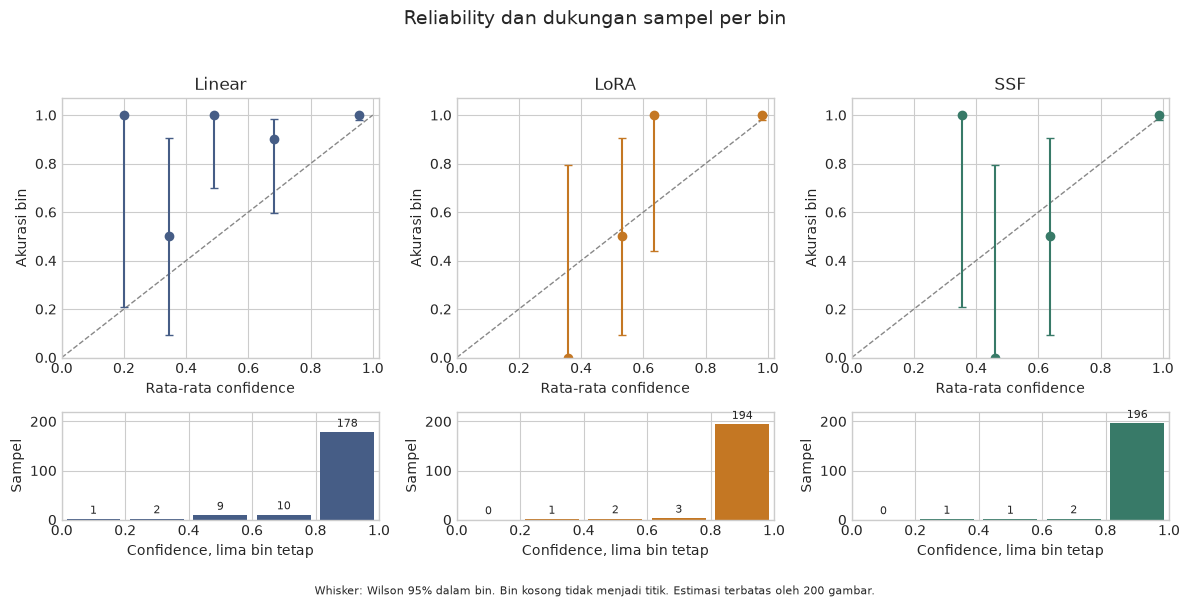

**Observasi:** rata-rata confidence kelas prediksi adalah 91.2% pada Linear, 97.0% pada LoRA, dan 97.7% pada SSF, sementara accuracy ketiganya 99%. Linear memberi probabilitas yang lebih konservatif secara agregat pada split ini. Penilaian calibration tetap memerlukan pembacaan distribusi bin, karena sebagian besar sampel berada pada bin confidence tinggi.

In [11]:
calibration_rows = []
for name, run in runs.items():
    frame = analysis.reliability_bins(run["probabilities"], run["targets"], bins=5)
    frame.insert(0, "method", name)
    calibration_rows.append(frame)
calibration = pd.concat(calibration_rows, ignore_index=True)
exports.table(calibration, "reliability-bins", "Hasil & Evaluasi",
              "Confidence, accuracy, jumlah sampel dan interval Wilson dalam lima bin.",
              "Bin kecil memiliki ketidakpastian besar. Bin kosong memiliki nilai tidak tersedia.")
show_asset(figures.reliability(runs), "reliability", "Hasil & Evaluasi",
           "Reliability plot dengan dukungan sampel per bin.",
           "Top-label calibration pada validation terbatas, tanpa calibration fitting.")
confidence = {name: run["probabilities"].max(axis=1).mean() for name, run in runs.items()}
display(Markdown(
    f"**Observasi:** rata-rata confidence kelas prediksi adalah {confidence['Linear']:.1%} pada Linear, "
    f"{confidence['LoRA']:.1%} pada LoRA, dan {confidence['SSF']:.1%} pada SSF, sementara accuracy ketiganya 99%. "
    "Linear memberi probabilitas yang lebih konservatif secara agregat pada split ini. "
    "Penilaian calibration tetap memerlukan pembacaan distribusi bin, karena sebagian besar sampel berada pada bin confidence tinggi."
))

### Paired Bootstrap untuk Selisih NLL

Paired bootstrap mengambil ulang 200 indeks gambar dengan replacement sebanyak 10.000 kali menggunakan seed analisis 42. Indeks yang sama dipakai bagi kedua model, sehingga perbandingan mempertahankan pasangan gambar.

Tabel menampilkan selisih NLL metode A dikurangi B dan interval percentile 95%. Selisih negatif berarti NLL A lebih rendah. Analisis ini bersifat post-hoc dan kondisional pada validation yang sudah tersedia.

In [12]:
nll_comparisons = analysis.paired_nll_bootstrap(runs, resamples=10000, seed=42)
exports.table(nll_comparisons, "paired-nll-bootstrap", "Hasil & Evaluasi",
              "Paired bootstrap selisih NLL dengan 10.000 resampling gambar.",
              "Tidak mencakup variasi seed training atau split baru.")
display(nll_comparisons[["method_a", "method_b", "delta_nll_a_minus_b", "ci95_low", "ci95_high"]].round(6).rename(columns={
    "method_a": "A", "method_b": "B", "delta_nll_a_minus_b": "Delta NLL (A-B)",
    "ci95_low": "CI95 lower", "ci95_high": "CI95 upper"}))
ssf_lora = nll_comparisons.loc[(nll_comparisons["method_a"] == "SSF") &
                               (nll_comparisons["method_b"] == "LoRA")].iloc[0]
crosses_zero = ssf_lora["ci95_low"] <= 0 <= ssf_lora["ci95_high"]
display(Markdown(
    f"**Interpretasi:** SSF-LoRA memiliki selisih NLL {ssf_lora['delta_nll_a_minus_b']:.5f}, "
    f"dengan interval [{ssf_lora['ci95_low']:.5f}, {ssf_lora['ci95_high']:.5f}]. "
    + ("Interval mencakup nol, sehingga data ini belum membedakan keduanya secara jelas. " if crosses_zero
       else "Interval tidak mencakup nol pada bootstrap gambar ini. ")
    + "Kesimpulan tetap terbatas pada sampel yang diamati dan belum menjadi bukti kestabilan antar seed."
))

,A,B,Delta NLL (A-B),CI95 lower,CI95 upper
0,LoRA,Linear,-0.075206,-0.103300,-0.049209
1,SSF,Linear,-0.080619,-0.110911,-0.051142
2,SSF,LoRA,-0.005413,-0.013901,0.003545


**Interpretasi:** SSF-LoRA memiliki selisih NLL -0.00541, dengan interval [-0.01390, 0.00355]. Interval mencakup nol, sehingga data ini belum membedakan keduanya secara jelas. Kesimpulan tetap terbatas pada sampel yang diamati dan belum menjadi bukti kestabilan antar seed.

### Per-class Recall

Accuracy memberi bobot lebih besar pada kelas yang memiliki lebih banyak gambar. Macro recall memberi bobot sama kepada setiap kelas yang teramati. Pada validation ini, satu gambar dapat menjadi seluruh support suatu kelas.

Tabel berikut dibatasi pada kelas yang memiliki error agar pola dapat diperiksa. CSV mencakup semua 102 kelas untuk setiap metode, termasuk kelas tanpa sampel dengan recall tidak tersedia.

In [13]:
recall_by_class = analysis.class_recall_table(runs, snapshot)
exports.table(recall_by_class, "class-recall", "Hasil & Evaluasi",
              "Support training/validation dan recall setiap kelas pada tiga metode.",
              "Macro recall hanya mencakup kelas dengan support validation lebih besar dari nol.")
error_classes = sorted(set(int(y) for run in runs.values()
                           for y in run["targets"][run["predicted"] != run["targets"]]))
recall_detail = recall_by_class.pivot(index="class_id", columns="method", values="recall").loc[error_classes]
supports = recall_by_class.loc[recall_by_class["method"] == "Linear"].set_index("class_id")
recall_detail = supports.loc[error_classes, ["training_support", "validation_support"]].join(recall_detail)
display(recall_detail.round(4).rename(columns={"training_support": "Train", "validation_support": "Validation"}))
macro = summary.set_index("method")["macro_recall_observed_percent"]
display(Markdown(
    f"**Observasi:** macro recall adalah {macro['Linear']:.2f}% untuk Linear, "
    f"{macro['LoRA']:.2f}% untuk LoRA, dan {macro['SSF']:.2f}% untuk SSF atas 90 kelas yang teramati. "
    "Accuracy yang sama dapat menyertai recall per kelas yang berbeda. "
    "Urutan ini sensitif terhadap support yang kecil dan tidak mengukur performa pada 12 kelas tanpa sampel."
))

,Train,Validation,Linear,LoRA,SSF
class_id,,,,,
30,6,3,0.6667,1.0,1.0
42,9,5,0.8000,0.8,1.0
67,6,1,1.0000,0.0,0.0
97,9,2,1.0000,1.0,0.5


**Observasi:** macro recall adalah 99.41% untuk Linear, 98.67% untuk LoRA, dan 98.33% untuk SSF atas 90 kelas yang teramati. Accuracy yang sama dapat menyertai recall per kelas yang berbeda. Urutan ini sensitif terhadap support yang kecil dan tidak mengukur performa pada 12 kelas tanpa sampel.

<a id="sec-diskusi"></a>

## Diskusi

### Error Diversity

Prediction disagreement menghitung gambar dengan kelas prediksi berbeda. Error overlap menghitung gambar yang salah pada kedua metode. Perbandingan memakai 200 gambar dan urutan label yang sama.

Panel foto memuat seluruh gambar unik yang salah pada setidaknya satu metode. Confidence menunjukkan probabilitas kelas yang diprediksi. Hijau menandai benar dan merah menandai salah.

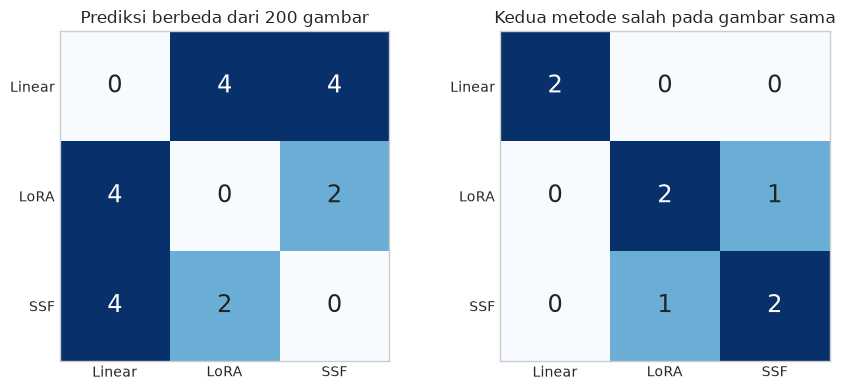

,A,B,Prediksi berbeda,Keduanya salah,Hanya A salah,Hanya B salah
0,Linear,LoRA,4,0,2,2
1,Linear,SSF,4,0,2,2
2,LoRA,SSF,2,1,1,1


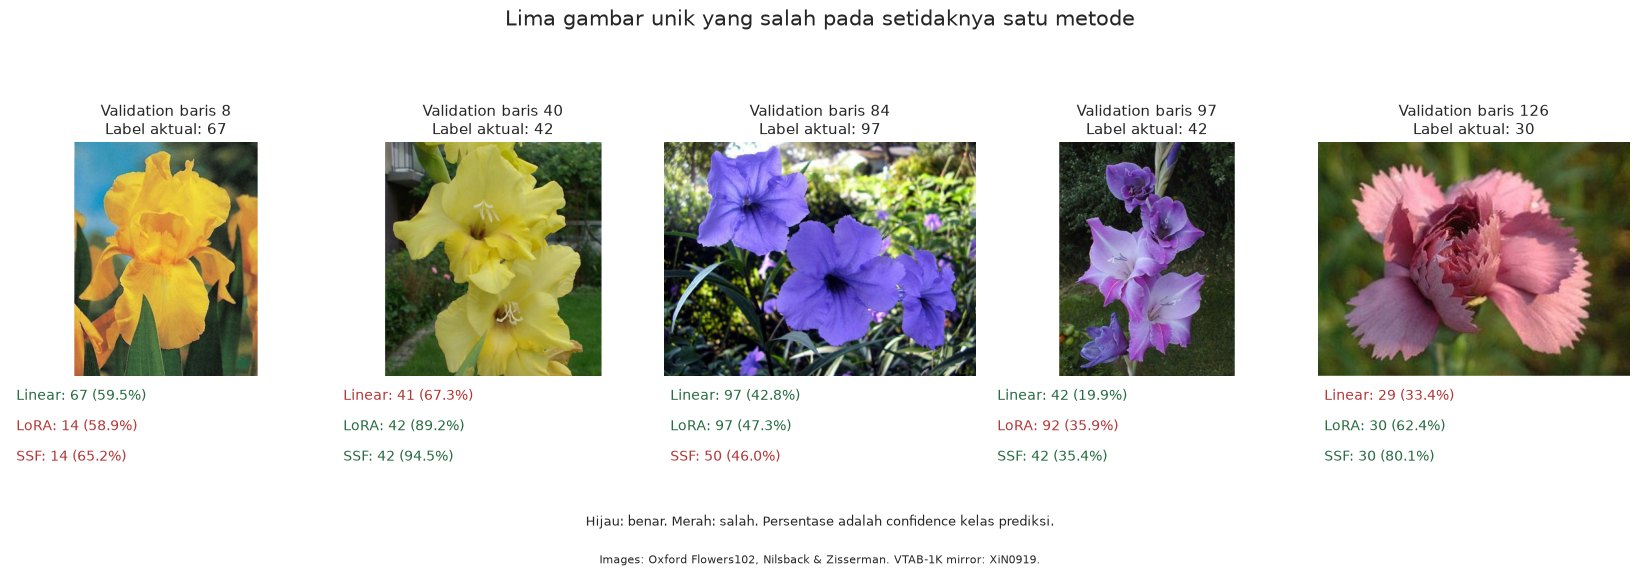

In [14]:
disagreement, overlap, pairwise = analysis.prediction_comparisons(runs)
for frame, name, caption in [(disagreement, "prediction-disagreement", "Jumlah kelas prediksi berbeda per pasangan."),
                             (overlap, "shared-errors", "Jumlah gambar yang salah pada kedua metode.")]:
    exports.table(frame.rename_axis("method").reset_index(), name, "Diskusi", caption,
                  "Hitungan deskriptif dari validation yang sama.")
exports.table(pairwise, "pairwise-comparison", "Diskusi", "Perbandingan disagreement dan error per pasangan.",
              "Error berbeda tidak menjamin peningkatan pada data baru.")
show_asset(figures.disagreement_matrices(disagreement, overlap), "prediction-comparison", "Diskusi",
           "Disagreement prediksi dan error overlap.",
           "Tidak membuktikan perbedaan inductive bias secara kausal.")
display(pairwise.rename(columns={"method_a": "A", "method_b": "B", "different_predictions": "Prediksi berbeda",
                                 "both_wrong": "Keduanya salah", "only_a_wrong": "Hanya A salah", "only_b_wrong": "Hanya B salah"}))
cases = analysis.error_cases(runs, snapshot)
exports.table(cases, "validation-error-cases", "Diskusi",
              "Semua error unik dengan label aktual, prediksi, confidence dan support kelas.",
              "Label merupakan indeks kelas dataset.", "Original photos and validation_last.npz")
show_asset(figures.error_images(cases, snapshot), "validation-errors", "Diskusi",
           "Lima foto yang salah pada setidaknya satu metode.",
           "Panel tidak membuktikan penyebab kesalahan.", "Oxford Flowers102 and verified validation logits")
for _, case in cases.iterrows():
    fig = figures.individual_error(case, snapshot)
    exports.figure(fig, f"error-row-{int(case['validation_row']):03d}", "Diskusi",
                   f"Validation baris {int(case['validation_row'])}: label dan prediksi tiga metode.",
                   "Confidence kelas prediksi.", "Oxford Flowers102 and validation logits")
    plt.close(fig)

Setiap metode salah pada dua gambar. Linear dan LoRA tidak berbagi error, sedangkan LoRA dan SSF berbagi satu. Dua error per metode belum cukup untuk menyimpulkan error diversity yang sistematis. Karena total error kecil, perbedaan beberapa gambar memiliki pengaruh besar pada hasil agregasi. Ensemble beberapa seed dari metode yang sama belum diuji sebagai kontrol keragaman.

Baris 40 dan 97 memiliki label aktual yang sama, yaitu 42, dengan bunga berwarna kuning dan ungu. Linear benar pada baris 97 dan salah pada 40. LoRA memperlihatkan pola sebaliknya, sedangkan SSF benar pada keduanya. Panel menunjukkan variasi penampilan dan perbedaan error. Pengaruh warna belum diisolasi melalui eksperimen.

Linear benar pada baris 97 dengan confidence sekitar 19,9%, tetapi salah pada baris 40 dengan confidence sekitar 67,3%. Confidence merupakan skor model dan tidak menjamin kebenaran. Temuan ini relevan untuk rancangan confidence gate yang memerlukan calibration dan evaluasi terpisah.

### Probability Averaging dan Logit Averaging

Paper membahas error diversity pada bagian 4. Caption Figure 4 menyebut majority vote, sementara rincian Figure 4 dalam Appendix C menjelaskan average logits. Perbandingan ini merujuk [rincian tersebut](https://arxiv.org/html/2409.16434v5) dan menampilkan dua aturan secara eksplisit:

$$p_{\mathrm{prob}}=\frac{1}{M}\sum_m\mathrm{softmax}(z_m),\qquad
p_{\mathrm{logit}}=\mathrm{softmax}\left(\frac{1}{M}\sum_m z_m\right).$$

Softmax bersifat nonlinear, sehingga kedua aturan umumnya menghasilkan probabilitas berbeda. Logit averaging juga dipengaruhi skala logits tiap model. Seluruh pasangan dan kombinasi tiga model diuji dengan bobot seragam, tanpa optimasi bobot, temperature, atau threshold.

Validation sudah diamati sebelumnya. Hasil agregasi merupakan eksplorasi pada data yang sama dan tidak menggantikan evaluasi independen.

,Agregasi,Anggota,Benar,Accuracy (%),NLL,Brier
0,Probability averaging,Linear + LoRA,200,100.0,0.07343,0.01956
1,Probability averaging,Linear + SSF,199,99.5,0.06974,0.01888
2,Probability averaging,LoRA + SSF,199,99.5,0.03780,0.01285
3,Probability averaging,Linear + LoRA + SSF,199,99.5,0.05922,0.01581
4,Logit averaging,Linear + LoRA,200,100.0,0.05614,0.01437
5,Logit averaging,Linear + SSF,199,99.5,0.05001,0.01381
6,Logit averaging,LoRA + SSF,199,99.5,0.03439,0.01184
7,Logit averaging,Linear + LoRA + SSF,199,99.5,0.04288,0.01201


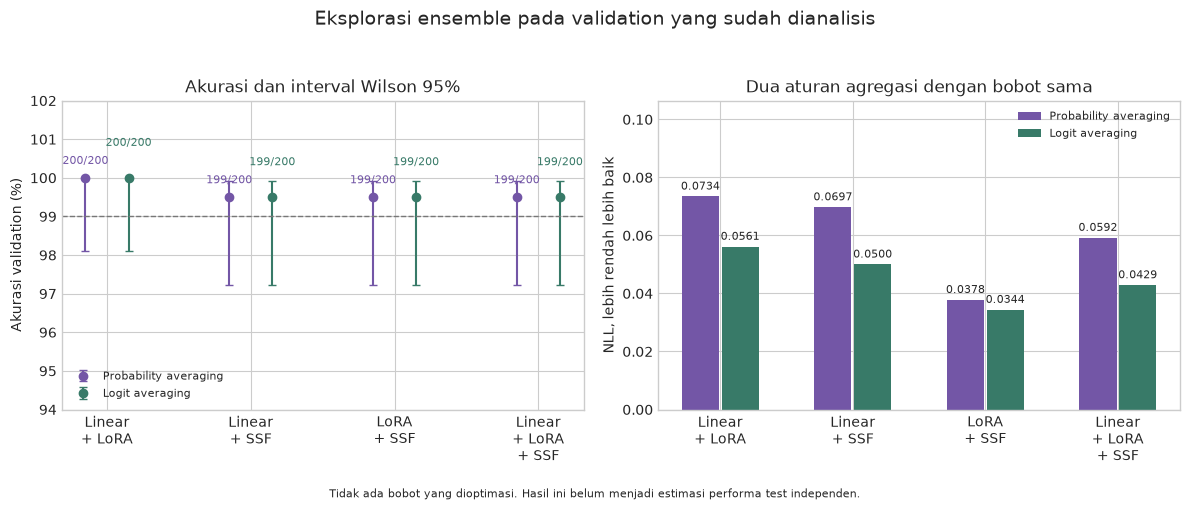

**Observasi:** probability averaging Linear-LoRA benar 200/200, dengan NLL 0.0734. NLL LoRA tunggal adalah 0.0410. Dibanding 198/200 pada masing-masing model, accuracy naik dua gambar, tetapi NLL lebih buruk daripada LoRA tunggal. Kedua aturan agregasi mencapai jumlah benar yang sama untuk setiap kombinasi pada split ini. Logit averaging memberi NLL lebih rendah pada 4 dari 4 kombinasi. Menambah SSF ke pasangan Linear-LoRA juga tidak meningkatkan accuracy. Hasil ini eksploratif pada validation yang sudah dianalisis, tanpa evaluasi independen.

In [15]:
ensembles = analysis.ensemble_table(runs)
exports.table(ensembles, "exploratory-ensembles", "Diskusi",
              "Empat kombinasi anggota dibandingkan dengan probability averaging dan logit averaging.",
              "Delapan hasil eksplorasi pada validation yang sudah dianalisis.")
display(ensembles[["aggregation", "ensemble", "correct", "accuracy_percent", "nll", "brier_multiclass_sum"]]
        .replace({"aggregation": {"probability_mean": "Probability averaging", "logit_mean": "Logit averaging"}})
        .round(5).rename(columns={"aggregation": "Agregasi", "ensemble": "Anggota", "correct": "Benar",
                                  "accuracy_percent": "Accuracy (%)", "nll": "NLL", "brier_multiclass_sum": "Brier"}))
show_asset(figures.ensemble_results(ensembles), "exploratory-ensembles", "Diskusi",
           "Accuracy dan NLL dari dua aturan agregasi.",
           "Tidak ada pemilihan bobot atau hasil test independen.")
mean_pair = ensembles.loc[(ensembles["aggregation"] == "probability_mean") &
                           (ensembles["ensemble"] == "Linear + LoRA")].iloc[0]
prob_nll = ensembles.loc[ensembles["aggregation"] == "probability_mean"].set_index("ensemble")["nll"]
logit_nll = ensembles.loc[ensembles["aggregation"] == "logit_mean"].set_index("ensemble")["nll"]
lower_nll_count = int((logit_nll < prob_nll).sum())
display(Markdown(
    f"**Observasi:** probability averaging Linear-LoRA benar {int(mean_pair['correct'])}/200, "
    f"dengan NLL {mean_pair['nll']:.4f}. NLL LoRA tunggal adalah {runs['LoRA']['metrics']['nll']:.4f}. "
    "Dibanding 198/200 pada masing-masing model, accuracy naik dua gambar, tetapi NLL lebih buruk daripada LoRA tunggal. Kedua aturan agregasi mencapai jumlah benar yang sama "
    f"untuk setiap kombinasi pada split ini. Logit averaging memberi NLL lebih rendah pada {lower_nll_count} dari {len(prob_nll)} kombinasi. "
    "Menambah SSF ke pasangan Linear-LoRA juga tidak meningkatkan accuracy. Hasil ini eksploratif pada validation yang sudah dianalisis, tanpa evaluasi independen."
))

In [16]:
findings = pd.DataFrame([
    {"Temuan paper": "Metode PEFT yang dituning dapat memiliki accuracy berdekatan",
     "Bukti checkpoint": "Linear, LoRA dan SSF sama-sama 198/200 pada konfigurasi tetap",
     "Batas": "Satu task, satu seed, tanpa tuning atau full fine-tuning"},
    {"Temuan paper": "Metode berbeda dapat menghasilkan prediksi yang saling melengkapi",
     "Bukti checkpoint": "Linear-LoRA tidak berbagi error dan mean keduanya benar 200/200",
     "Batas": "Hanya lima error unik dan validation yang telah diamati"},
    {"Temuan paper": "Ensemble dapat memanfaatkan perbedaan prediksi",
     "Bukti checkpoint": "Dua aturan averaging memiliki NLL berbeda, jumlah benar sama",
     "Batas": "Tidak mereproduksi ensemble seluruh metode pada test paper"},
    {"Temuan paper": "Many-shot, full fine-tuning dan robustness terhadap distribution shift",
     "Bukti checkpoint": "Belum diuji",
     "Batas": "Tidak menjadi klaim hasil checkpoint ini"},
])
exports.table(findings, "paper-findings", "Diskusi", "Hubungan temuan paper dan bukti checkpoint.",
              "Kesesuaian lokal belum mereplikasi seluruh kesimpulan paper.", "Mai et al. sections 3-7 and current results")
display(findings)

,Temuan paper,Bukti checkpoint,Batas
0,Metode PEFT yang dituning dapat memiliki accuracy berdekatan,"Linear, LoRA dan SSF sama-sama 198/200 pada konfigurasi tetap","Satu task, satu seed, tanpa tuning atau full fine-tuning"
1,Metode berbeda dapat menghasilkan prediksi yang saling melengkapi,Linear-LoRA tidak berbagi error dan mean keduanya benar 200/200,Hanya lima error unik dan validation yang telah diamati
2,Ensemble dapat memanfaatkan perbedaan prediksi,"Dua aturan averaging memiliki NLL berbeda, jumlah benar sama",Tidak mereproduksi ensemble seluruh metode pada test paper
3,"Many-shot, full fine-tuning dan robustness terhadap distribution shift",Belum diuji,Tidak menjadi klaim hasil checkpoint ini


### Resource dan batas interpretasi

Frozen berarti bobot pretrained tidak diperbarui optimizer. Ketika LoRA atau SSF dilatih di dalam backbone, propagasi gradien tetap melewati operasi model. Dengan demikian, jumlah parameter yang dilatih tidak langsung menentukan kebutuhan aktivasi, memori proses, atau latency.

Durasi berikut merupakan jumlah waktu training dan validation pada epoch yang tercatat. Startup, penyimpanan checkpoint setelah pengukuran epoch, waktu tunggu resource, dan interupsi tidak seluruhnya tercakup. Rata-rata per epoch ditampilkan dengan satuan detik.

Linear memakai batch langsung 64, sedangkan LoRA dan SSF memakai accumulation. Node juga dipakai bersama dan kebijakan allocator berbeda. Angka resource berfungsi sebagai catatan operasional, tanpa ranking efisiensi intrinsik.

In [17]:
resource_columns = ["method", "trainable_including_head", "observed_total_epoch_minutes",
                    "observed_mean_epoch_seconds", "observed_peak_gpu_allocated_mib",
                    "observed_peak_process_rss_mib"]
exports.table(summary[resource_columns], "observed-resources", "Diskusi",
              "Total durasi epoch, rata-rata per epoch dan peak memory yang tercatat.",
              "Pengukuran bukan wall-clock seluruh proses dan kondisi node tidak terkontrol.")
display(summary[resource_columns].round(2).rename(columns={
    "method": "Metode", "trainable_including_head": "Parameter dilatih",
    "observed_total_epoch_minutes": "Total epoch (min)", "observed_mean_epoch_seconds": "Mean epoch (s)",
    "observed_peak_gpu_allocated_mib": "GPU allocated (MiB)", "observed_peak_process_rss_mib": "Peak RSS (MiB)"}))

,Metode,Parameter dilatih,Total epoch (min),Mean epoch (s),GPU allocated (MiB),Peak RSS (MiB)
0,Linear,78438,17.56,10.54,815.56,3351.98
1,LoRA,373350,64.94,38.96,1118.35,3058.50
2,SSF,284262,69.40,41.64,1699.09,3151.72


### Keterbatasan

Eksperimen memakai satu seed dan satu konfigurasi per metode. Hyperparameter search, full fine-tuning, dan retraining pada gabungan 1.000 gambar belum dilakukan. Performa yang dilaporkan adalah validation epoch 100, sehingga tidak langsung sebanding dengan test paper.

Validation kecil, hanya mencakup 90 kelas, dan sudah digunakan untuk analisis hasil. Wilson interval dan bootstrap gambar tidak mencakup variasi training atau split baru. Jumlah error yang sedikit juga membatasi kekuatan kesimpulan tentang pola error diversity.

Mirror memiliki integritas file yang diperiksa, tetapi exact membership terhadap arsip penulis belum terverifikasi. Dataset saat ini tidak dinyatakan memiliki label noise. Klaim mengenai penyebab error, manfaat normalization, atau pengaruh rank memerlukan eksperimen terkontrol.

<a id="sec-kesimpulan"></a>

## Kesimpulan

In [18]:
display(Markdown(
    f"1. **Perbandingan metode:** semua metode benar 198/200 pada epoch 100. Linear melatih parameter paling sedikit. "
    f"LoRA dan SSF memiliki NLL serta Brier lebih rendah. SSF memiliki NLL titik estimasi terendah "
    f"({runs['SSF']['metrics']['nll']:.4f}), sementara interval selisih SSF-LoRA "
    + ("masih mencakup nol. " if crosses_zero else "tidak mencakup nol pada bootstrap gambar ini. ")
    + "Macro recall memberi urutan berbeda dengan dukungan per kelas yang terbatas. Konfigurasi belum dituning per metode, sehingga hasil tidak menetapkan pemenang keseluruhan.\n\n"
    "2. **Error diversity:** pasangan Linear-LoRA tidak berbagi gambar error. Dua error per metode hanya mendukung deskripsi "
    "perbedaan prediksi pada lingkup validation yang digunakan.\n\n"
    "3. **Agregasi:** kedua aturan memberi 200/200 pada Linear-LoRA dan 199/200 pada kombinasi lainnya. "
    "Linear-LoRA probability averaging memiliki NLL 0,0734, lebih buruk daripada LoRA tunggal 0,0410. Manfaat pada data baru dan efisiensi inferensi belum diukur."
))

1. **Perbandingan metode:** semua metode benar 198/200 pada epoch 100. Linear melatih parameter paling sedikit. LoRA dan SSF memiliki NLL serta Brier lebih rendah. SSF memiliki NLL titik estimasi terendah (0.0356), sementara interval selisih SSF-LoRA masih mencakup nol. Macro recall memberi urutan berbeda dengan dukungan per kelas yang terbatas. Konfigurasi belum dituning per metode, sehingga hasil tidak menetapkan pemenang keseluruhan.

2. **Error diversity:** pasangan Linear-LoRA tidak berbagi gambar error. Dua error per metode hanya mendukung deskripsi perbedaan prediksi pada lingkup validation yang digunakan.

3. **Agregasi:** kedua aturan memberi 200/200 pada Linear-LoRA dan 199/200 pada kombinasi lainnya. Linear-LoRA probability averaging memiliki NLL 0,0734, lebih buruk daripada LoRA tunggal 0,0410. Manfaat pada data baru dan efisiensi inferensi belum diukur.

<a id="sec-future-works"></a>

## Future Works

### A. Confidence-based Selective Fusion

Linear-LoRA tidak berbagi dua error masing-masing pada validation ini. Pola tersebut memotivasi pengujian selective fusion, dengan error diversity yang masih perlu diperiksa pada data baru. Usulannya adalah menjalankan Linear terlebih dahulu dan menggunakan LoRA beserta fusion untuk input yang belum memenuhi aturan calibrated confidence. Temperature dan gate ditentukan pada calibration data yang terpisah dari evaluasi akhir. Probability averaging dan logit averaging diuji sebagai ablation aturan fusion, sehingga hasil validation saat ini tidak langsung mengunci pilihan agregasi.

Kedua metode tetap memakai backbone ViT penuh. Jika proporsi fallback adalah $r$, jumlah forward pass rata-rata per gambar adalah $1+r$, ditambah biaya gate dan pengelolaan model. Ini bukan rasio latency. Potensi penghematan dinilai terhadap ensemble dua model yang selalu aktif, sambil tetap membandingkan dengan LoRA tunggal.

Pembanding mencakup single model sebelum dan sesudah temperature scaling, ensemble beberapa seed dari metode yang sama, always-on averaging, routing acak dengan anggaran sama, dan gate tanpa calibration. Ensemble classifier Linear dapat berbagi satu forward backbone saat inferensi. Evaluasi mencakup accuracy, NLL, Brier, risk-coverage, pemanggilan model kedua, memory residency, dan latency aktual. Selective fusion diteruskan jika memberi trade-off quality-latency yang berguna terhadap calibrated single model dan always-on averaging, dengan batas kualitas serta resource ditetapkan sebelum evaluasi. Arah ini menjadi prioritas. EulerLoRA serta studi routing expert PEFT menjadi pembanding literatur.

### B. Class-preserving Sample Weighting

Training memiliki 5-10 gambar per kelas. Usulkan bobot kesulitan relatif di dalam kelas dengan batas minimum kontribusi kelas ketika imbalance dan label noise dibuat secara terkontrol hanya pada training. Dataset sekarang tidak dianggap berisik tanpa bukti.

Bandingkan plain LoRA, class weighting, global noise weighting, within-class weighting, dan kontrol SSF. Ukur macro-F1, balanced accuracy, recall head/tail, dan NLL pada evaluasi bersih. Paper Ma et al. tentang noisy-label PEFT menjadi pembanding, dengan pendalaman full text sebelum mengunci perbedaan mekanisme.

### C. Resource-aware PEFT Configuration Selection

Usulkan profiling singkat untuk menyaring konfigurasi yang memenuhi anggaran host/GPU, lalu memilih dengan kualitas validation dan biaya total. Bandingkan pemilihan berdasarkan accuracy, parameter count, resource, dan aturan gabungan. Kontrol precision, effective batch, jumlah update, serta biaya profiling.

Arah ini menjadi alternatif praktis terhadap batas studi paper yang tidak berfokus pada memory dan FLOPs. Studi fixed-budget PET menjadi pembanding. Ketiga usulan belum dievaluasi. Rancangan lanjutan tersedia pada [arah penelitian](https://github.com/alifnw/peft-vision-flowers102/blob/main/docs/RESEARCH_DIRECTIONS.md).

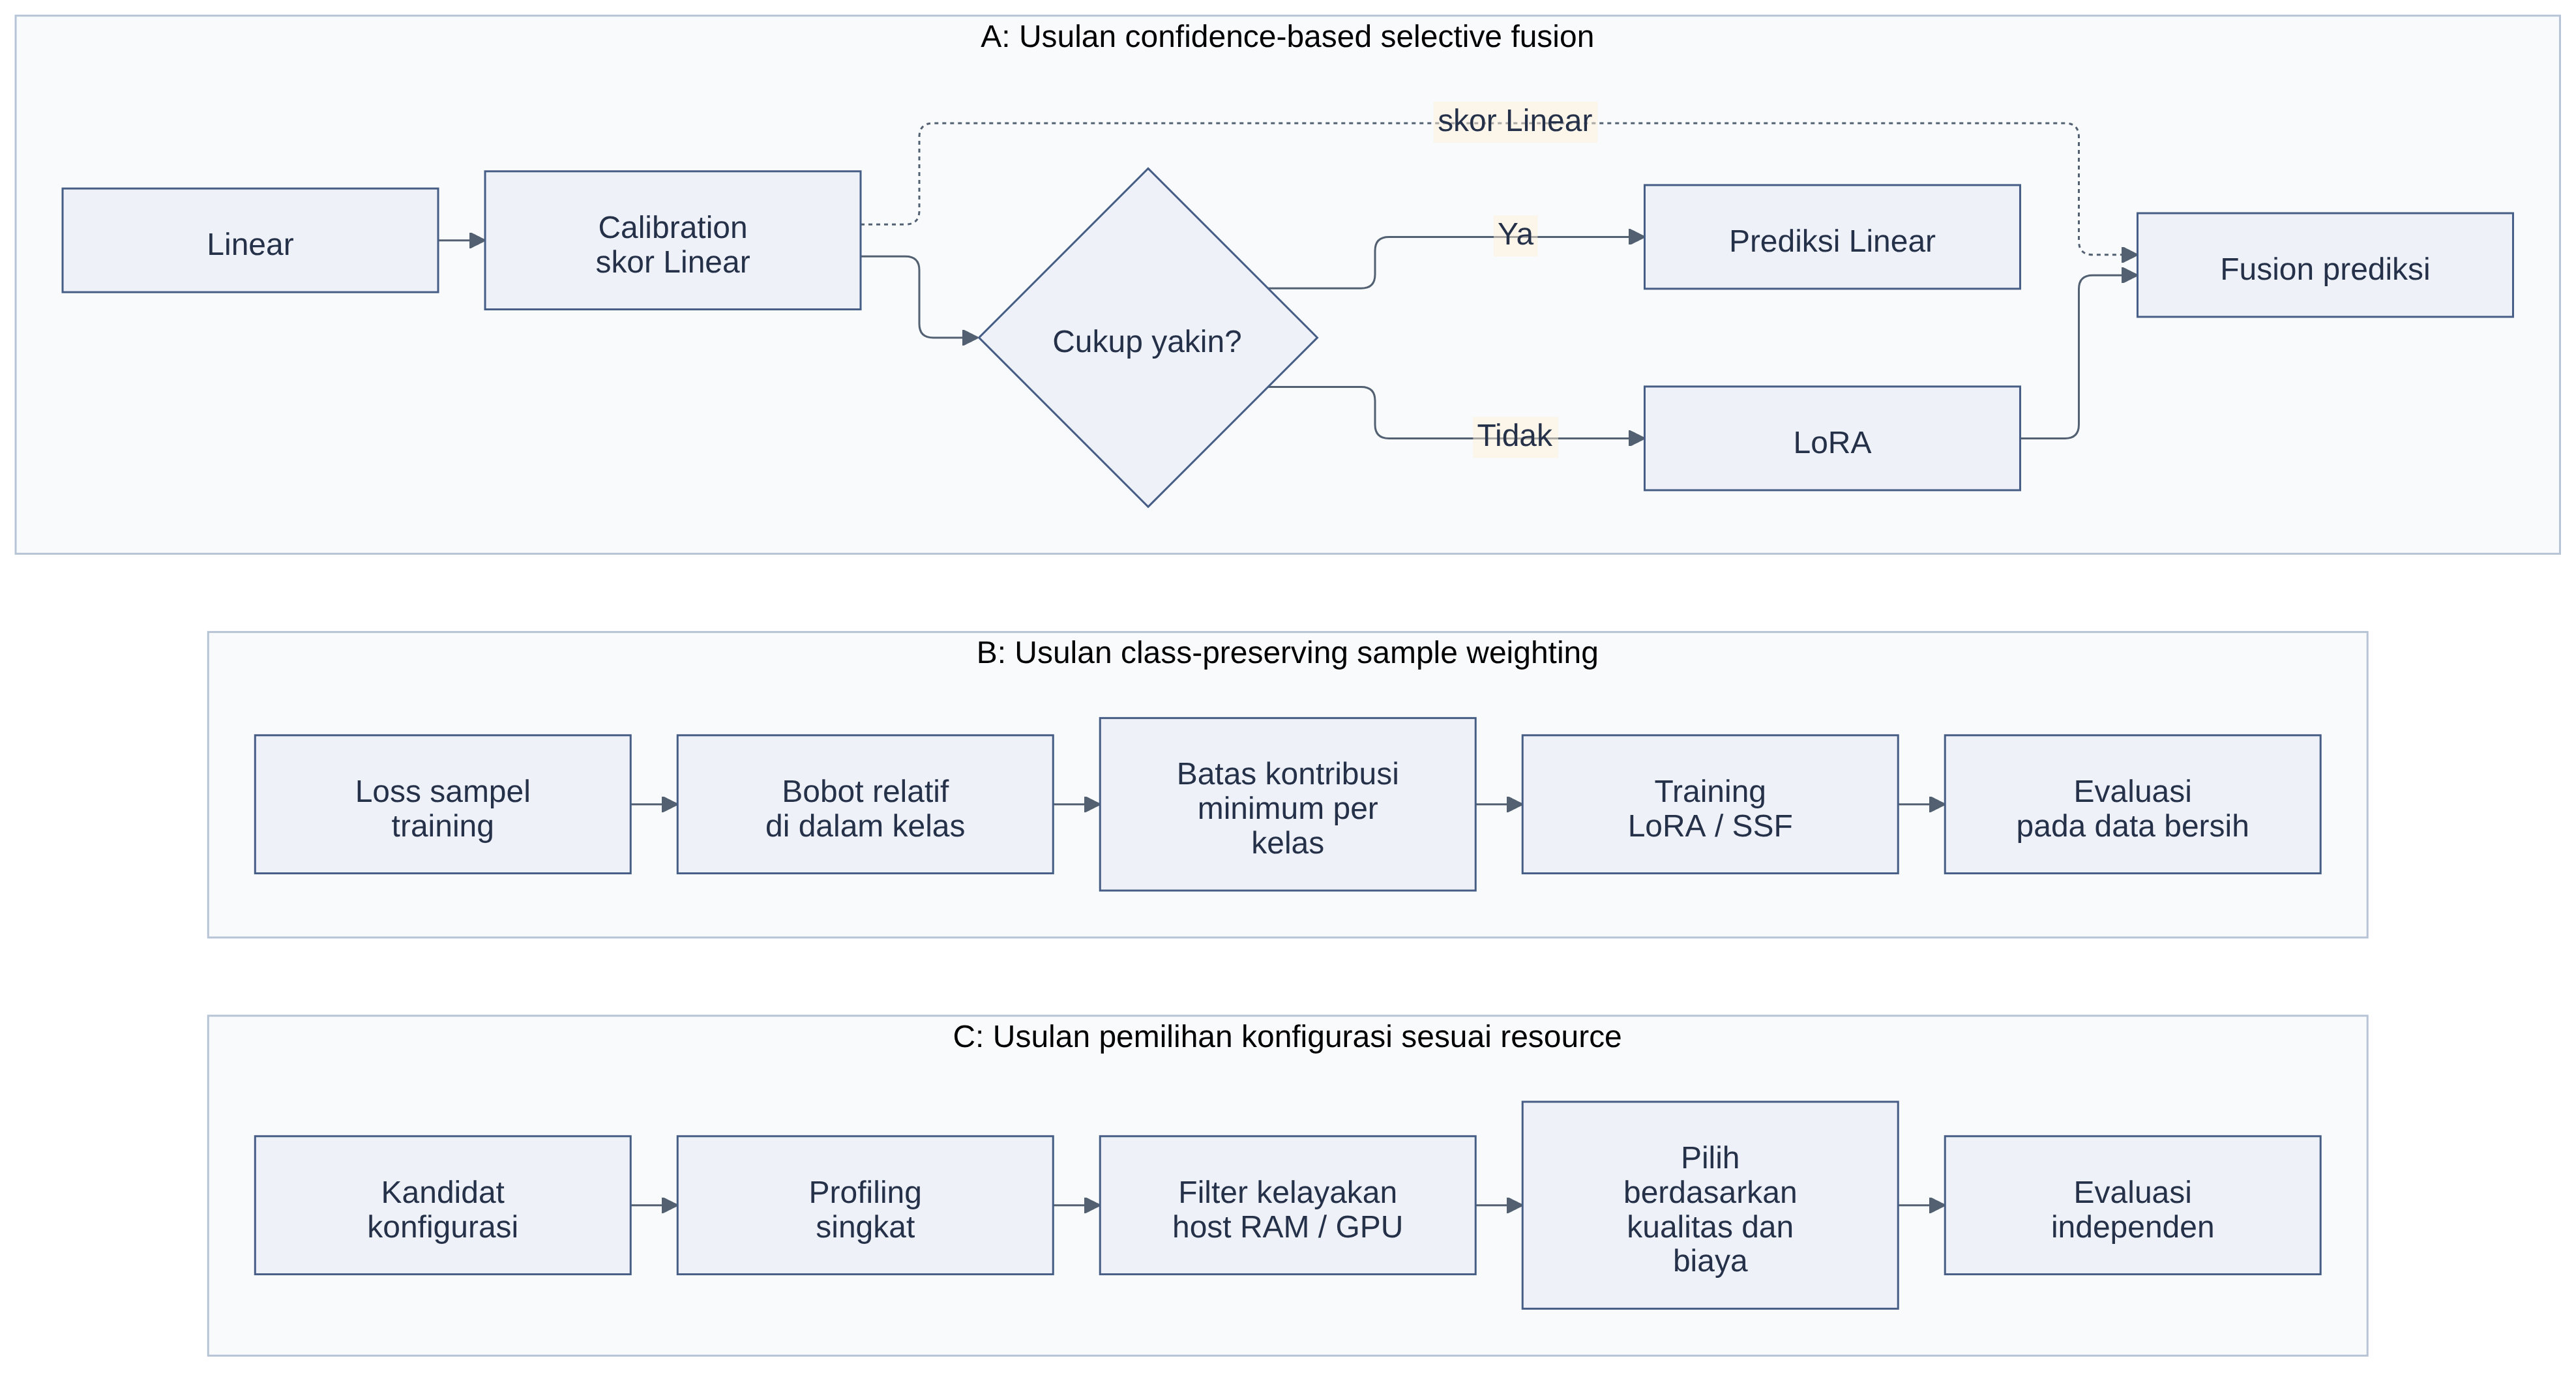

In [19]:
show_diagram("research-directions", "Future Works",
           "Mekanisme tiga usulan eksperimen lanjutan.",
           "Tidak ada hasil evaluasi gate, noise weighting atau resource selector.",
           "Current validation evidence and cited related work")
directions = pd.DataFrame([
    {"arah": "A: Selective fusion", "prioritas": "Utama",
     "mekanisme": "Confidence gate mengaktifkan LoRA dan fusion untuk sebagian input",
     "pembanding": "Single model, always-on averaging, random routing, uncalibrated gate",
     "metrik": "Accuracy, NLL, Brier, risk-coverage, expert calls, latency"},
    {"arah": "B: Kontribusi kelas", "prioritas": "Eksperimen robustness",
     "mekanisme": "Within-class difficulty weights dengan minimum class contribution",
     "pembanding": "Plain LoRA, class weighting, global weighting, proposed weighting, SSF",
     "metrik": "Macro-F1, balanced accuracy, head/tail recall, NLL"},
    {"arah": "C: Konfigurasi sesuai resource", "prioritas": "Alternatif praktis",
     "mekanisme": "Profiling, feasibility filtering dan pemilihan kualitas/biaya",
     "pembanding": "Accuracy-only, parameter-only, resource-only, joint selection",
     "metrik": "Feasibility, quality, profiling cost, total runtime, peak memory"},
])
_ = exports.table(directions, "research-directions", "Future Works",
              "Mekanisme, pembanding dan metrik usulan eksperimen.",
              "Usulan belum dilatih atau dievaluasi.", "Current evidence and docs/RESEARCH_DIRECTIONS.md")

<a id="sec-output"></a>

## Output

Notebook dan source tersedia pada [repository proyek](https://github.com/alifnw/peft-vision-flowers102). Grafik PNG/SVG dan tabel CSV dihasilkan pada assets/checkpoint1. Diagram ditampilkan dari hasil render Mermaid yang tersimpan lokal, dengan sumber .mmd pada assets/checkpoint1/diagrams. Setiap file dicatat bersama sumber, bagian notebook, keterangan, batas interpretasi, dan SHA-256 dalam [manifest hasil](https://github.com/alifnw/peft-vision-flowers102/blob/main/assets/checkpoint1/asset_index.csv).

Checkpoint training ketiga metode tersimpan pada A100. File model belum dipublikasikan sebagai unduhan. Hasil analisis menggunakan snapshot logits dan history, dengan provenance pada results/checkpoint1.

In [20]:
references = json.loads((ROOT / "docs/references.json").read_text())["references"]
exports.table(pd.DataFrame(references), "references", "Output",
              "Sumber paper, kode dan dataset beserta lingkup pembacaan.",
              "Tidak semua full text pembanding telah ditelaah.", "Primary sources and verified metadata")
asset_index = exports.finalize()
print("Ekspor terverifikasi:", len(asset_index), "file hasil dan sumber diagram")
print("Manifest: assets/checkpoint1/asset_index.csv")

Ekspor terverifikasi: 59 file hasil dan sumber diagram
Manifest: assets/checkpoint1/asset_index.csv


### Referensi

1. Mai et al. (CVPR 2025). [Lessons and Insights from a Unifying Study of Parameter-Efficient Fine-Tuning in Visual Recognition](https://arxiv.org/abs/2409.16434), khususnya bagian 3, bagian 4, dan Appendix A.
2. [Implementasi resmi yang dipin pada commit cea7e21b2ddecef8172f5d177da5a29d531c4279](https://github.com/OSU-MLB/ViT_PEFT_Vision/tree/cea7e21b2ddecef8172f5d177da5a29d531c4279).
3. Nilsback dan Zisserman. [Oxford Flowers102](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/).
4. [XiN0919/VTAB-1k mirror](https://huggingface.co/datasets/XiN0919/VTAB-1k), revisi a1c257fbbeebd3260c0a201fe6a6c9916b56eee7. Atribusi gambar dan hash tersedia pada snapshot input.
5. Anumasa dan Liu (2026). [EulerLoRA](https://arxiv.org/abs/2608.01142), arXiv preprint.
6. Lotfi et al. (2026). [Trade-offs in Ensembling, Merging and Routing Among Parameter-Efficient Experts](https://www.microsoft.com/en-us/research/publication/trade-offs-in-ensembling-merging-and-routing-among-parameter-efficient-experts/), konteks LLM.
7. Ma, Pan dan Wei (ICMR 2026). [Unveiling PEFT Robustness to Noisy Labels in VLMs](https://doi.org/10.1145/3805622.3810828). Metadata dan abstract diperiksa, full text belum ditelaah.
8. Khan dan Siddique (2025). [Fixed-Budget Parameter-Efficient Training with Frozen Encoders Improves Multimodal Chest X-Ray Classification](https://arxiv.org/abs/2512.21508), ICCIT 2025 sebagaimana dinyatakan pada arXiv record.